# Experiment: Gesture Classification with Deep Learning

In this experiment, a neural network model is trained with EMG data from the Hyser database to classify gestures. Here, a subset of the EMG channels is used to have the configuration/organization of that of the armband developed for this project. The data are divided into training and validation data to train the model, and into test data to evaluate the classification performance of the trained model.

# Signal preprocessing

The folowing 4-step preprocessing is applied to the EMG signal data:
1. Rectification
2. Teager-Kaiser Energy Operator (TKE)
3. Moving Average (30 samples)

The normalization step is applied during the training while the other ones have already been applied to the data. 

## Table of Contents

- [0. Import libraries](#0)
- [1. Config Variables and hyperparameters](#1)
- [2. Load dataset with dataloader](#2)
- [3. Create model to train](#3)
- [4. Training](#4)
- [5. Evaluate best model](#5)
- [6. Save the model in .H5 file](#6)


<a name="0"></a>
# Import Libraries

In [1]:
import os, sys

processing_source_path = os.path.abspath('./../../../Processing/')
if(processing_source_path not in sys.path):
    sys.path.append(processing_source_path)
import ProcessingPipeline as pp

dataloader_source_path = os.path.abspath('./../../../Dataloader/')
if(dataloader_source_path not in sys.path):
    sys.path.append(dataloader_source_path)
from EMGGestureDataGen import EMGGestureDataGen

dataloader_source_path = os.path.abspath('./../../../Dataloader/')
if(dataloader_source_path not in sys.path):
    sys.path.append(dataloader_source_path)
from EMGGestureDataGen import EMGGestureDataGen
from KerasDataPipeline import KerasDataPipeline

model_source_path = os.path.abspath('./../../../Keras_deep_models/')
if(model_source_path not in sys.path):
    sys.path.append(model_source_path)
from EMGConv2DResNetModel import EMGConv2DResNetModel

dataloader_source_path = os.path.abspath('./../../../Utils/')
if(dataloader_source_path not in sys.path):
    sys.path.append(dataloader_source_path)
import utils as utils
import available_metrics as metrics

In [2]:
import numpy as np
from os.path import join
import datetime
import matplotlib.pyplot as plt
import pandas as pd
import json

In [3]:
import tensorflow as tf
print(tf.__version__)
gpus = tf.config.list_physical_devices('GPU')
if gpus:
  try:
    # Currently, memory growth needs to be the same across GPUs
    for gpu in gpus:
      tf.config.experimental.set_memory_growth(gpu, True)
    logical_gpus = tf.config.list_logical_devices('GPU')
    print(len(gpus), "Physical GPUs,", len(logical_gpus), "Logical GPUs")
  except RuntimeError as e:
    # Memory growth must be set before GPUs have been initialized
    print(e)

2.9.1
8 Physical GPUs, 8 Logical GPUs


2026-08-31 20:41:37.195389: I tensorflow/core/platform/cpu_feature_guard.cc:194] This TensorFlow binary is optimized with oneAPI Deep Neural Network Library (oneDNN) to use the following CPU instructions in performance-critical operations:  SSE3 SSE4.1 SSE4.2 AVX
To enable them in other operations, rebuild TensorFlow with the appropriate compiler flags.
2026-08-31 20:41:44.987941: I tensorflow/core/common_runtime/gpu/gpu_process_state.cc:222] Using CUDA malloc Async allocator for GPU: 0
2026-08-31 20:41:44.988175: I tensorflow/core/common_runtime/gpu/gpu_device.cc:1532] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 51743 MB memory:  -> device: 0, name: NVIDIA A100-SXM4-80GB, pci bus id: 0000:07:00.0, compute capability: 8.0
2026-08-31 20:41:44.990185: I tensorflow/core/common_runtime/gpu/gpu_process_state.cc:222] Using CUDA malloc Async allocator for GPU: 1
2026-08-31 20:41:44.990305: I tensorflow/core/common_runtime/gpu/gpu_device.cc:1532] Created device /job:localh

<a name="1"></a>
# Config Variables and hyperparameters

In [4]:
# model_name = 'EMG65_2D_CNN_multiclass_armband_onesubject20230627_194533'
model_name = None

In [5]:
def _cbeb_data_root():
    """Processed and raw datasets live in <package>/data, or CBEB_DATA_ROOT."""
    import os
    from pathlib import Path
    env = os.environ.get("CBEB_DATA_ROOT")
    if env:
        return Path(env).resolve()
    pkg = Path.cwd().resolve()
    for _ in range(8):
        if (pkg / "README.md").exists() and (pkg / "EMG").exists():
            return (pkg / "data").resolve()
        if pkg.parent == pkg:
            break
        pkg = pkg.parent
    return (Path.cwd().resolve() / "data").resolve()

if model_name is None:
    print('Crate new config model')
    data_params = {
        "checkpoint_path": "trainings/",
        "database_path": "hyser_gestures_common_mono",#"Hyser_diff_ExtensorFlexor_2",
        "training_name": 'EMGHYSER_2D_CNN_multiclass_armband' + datetime.datetime.now().strftime("%Y%m%d_%H%M%S"),
        "img_width": 16,
        "img_height": 8,
        "num_features": 256,
        "window_step": 12,
        'armband': False,
        'norm':1, # by sampĺe, each sample belong the time
    }
    training_params = {
        "early_stopping_patient": 10,
        "epochs": 200,
        "batch_size": 256,
        "lr": 0.01,
        #"loss": 'CatCE',
        "loss": 'SparceCatCE',
        "filter_divisor": 4,
    }
    model_params = {
        "model_output_mode": 'multiclass',
        "print_model": True,
        "network_name": 'EMG_HysersEMG_2D_CNN_128f_128ch_SCE_normminmax_bysample_adamW',
        "optimizer": 'adamW',
        "channels": 128,
    }
    # Combine all categories into a single dictionary
    config_model = {**data_params, **model_params, **training_params}
    
    try:
        with open(join(str(_cbeb_data_root() / config_model['database_path']), 'train', 'dataset_param.json')) as json_file:
            dataset_param = json.load(json_file)
            config_model['num_classes'] = len(dataset_param['dataset']['gestures'])
    except:
         config_model['num_classes'] = 10
else:
    config_path = join('trainings/', model_name, 'training_param.json')
    print('Loading config model from:', config_path)
    with open(config_path) as json_file:
        config_model = json.load(json_file)
    
print(config_model)


Crate new config model
{'checkpoint_path': 'trainings/', 'database_path': 'hyser_gestures_common_mono', 'training_name': 'EMGHYSER_2D_CNN_multiclass_armband20260831_204145', 'img_width': 16, 'img_height': 8, 'num_features': 256, 'window_step': 12, 'armband': False, 'norm': 1, 'model_output_mode': 'multiclass', 'print_model': True, 'network_name': 'EMG_HysersEMG_2D_CNN_128f_128ch_SCE_normminmax_bysample_adamW', 'optimizer': 'adamW', 'channels': 128, 'early_stopping_patient': 10, 'epochs': 200, 'batch_size': 256, 'lr': 0.01, 'loss': 'SparceCatCE', 'filter_divisor': 4, 'num_classes': 10}


In [6]:
# Data root: download raw/preprocessed data under <package>/data (see docs/DATASETS.md)
# or export CBEB_DATA_ROOT=/path/to/data
from pathlib import Path as _Path
import os as _os
_pkg = _Path.cwd().resolve()
for _ in range(8):
    if (_pkg / "README.md").exists() and (_pkg / "EMG").exists():
        break
    _pkg = _pkg.parent
_DATA_ROOT = _Path(_os.environ.get("CBEB_DATA_ROOT", _pkg / "data")).resolve()
dataset_path = str(_DATA_ROOT / config_model["database_path"])
num_gestures = config_model['num_classes']
window_size = config_model['num_features']
window_step = config_model['window_step']
img_width = config_model['img_width']
img_height = config_model['img_height']
batch_size = config_model['batch_size']
num_emg_channels = config_model['channels']
armband= config_model['armband']


In [7]:
import glob
try:
    with open(join(dataset_path, 'train', 'dataset_param.json')) as json_file:
        dataset_param = json.load(json_file)
        gesture_list = dataset_param['dataset']['gestures']
        print(dataset_param)
except:
    with open('../../../DataBase_Treatment/gestures_comparison_65HD_Hyser.json', 'r', encoding='utf-8') as f:
        gestures = json.load(f)
    gesture_names = [g['hyser_label'] for g in gestures['gesture_mapping']]
    gesture_list = [int(g['hyser_id']) for g in gestures['gesture_mapping']]
    print(gesture_names)
    #print(glob.glob(join(dataset_path, 'train/*')))
    
#gesture_list, len(gesture_list)

{'name': 'HYSER_20260831_190748', 'dataset': {'name': 'data/hyser_gestures_common_mono', 'preprocessing': ['Retification', 'EMGTKE', 'MAFilter(31)'], 'subject': ['Subject01', 'Subject02', 'Subject03', 'Subject04', 'Subject05', 'Subject06', 'Subject07', 'Subject08', 'Subject09', 'Subject10', 'Subject11', 'Subject12', 'Subject13', 'Subject14', 'Subject15', 'Subject16', 'Subject17', 'Subject18', 'Subject19', 'Subject20'], 'session': [1, 2], 'gestures': [0, 1, 2, 3, 4, 5, 6, 7, 10, 11, 30, 31], 'repetition': [1, 2, 7], 'rest_repetition': 1, 'differential': False, 'window_size': 128}}


In [8]:
config_model['gesture_list'] = gesture_list
config_model['num_classes'] = len(gesture_list)

In [9]:
gesture_list

[0, 1, 2, 3, 4, 5, 6, 7, 10, 11, 30, 31]

<a name="2"></a>
# Load dataset with dataloader

In [10]:
data_processing = pp.ProcessingPipeline([
    pp.NormMinMax(axis=config_model['norm']), # initial shape: (batchsize, img_width*img_height, samples)
    pp.DataReshape((img_width, img_height, window_size)),
    #pp.LabelOneHot(np.sort(gesture_list)) # to multiclass 
    ])

train_dataset = EMGGestureDataGen(join(dataset_path, 'train/'), batch_size, window_size, window_step, num_emg_channels, processing=data_processing, armband=armband, dataset_name='Hyser')
val_dataset = EMGGestureDataGen(join(dataset_path, 'val/'), batch_size, window_size, window_step, num_emg_channels, processing=data_processing, armband=armband, dataset_name='Hyser')
test_dataset = EMGGestureDataGen(join(dataset_path, 'test/'), batch_size, window_size, window_step, num_emg_channels, processing=data_processing, armband=armband, dataset_name='Hyser')

In [11]:
batch_size

256

In [12]:
len(np.unique(val_dataset[0][1]))

12

In [13]:
np.unique(val_dataset[0][1])

array([ 0,  1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11])

In [14]:
# # UNCOMMENT TO USE CLASS WEIGHTS
# from sklearn.utils import class_weight

# class_weights = class_weight.compute_class_weight('balanced', classes=np.arange(len(gesture_list)), y=train_dataset.yData)
# config_model['class_weights'] = dict(enumerate(class_weights))

In [15]:
config_model['num_classes']

12

In [16]:
#train_dataset_pipeline = KerasDataPipeline(train_dataset, (None, img_width, img_height, window_size), [None, config_model['num_classes']])
#val_dataset_pipeline = KerasDataPipeline(val_dataset, (None, img_width, img_height, window_size), [None, config_model['num_classes']])

train_dataset_pipeline = KerasDataPipeline(train_dataset, (None, img_width, img_height, window_size), [None, ])
val_dataset_pipeline = KerasDataPipeline(val_dataset, (None, img_width, img_height, window_size), [None, ])

In [17]:
train_dataset[0];

In [18]:
print('(bach size, num_channels, window size')
test_dataset.__getitem__(0)[0].shape

(bach size, num_channels, window size


(256, 16, 8, 256)

In [19]:
test_dataset.yData[0]

0

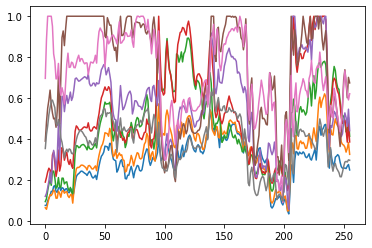

In [20]:
plt.plot(train_dataset[0][0][0,0,:].T)
plt.show()

In [21]:
train_dataset_pipeline.outputShape

[None]

In [22]:
train_dataset_pipeline.outputShape

[None]

In [23]:
config_model['num_classes']=len(np.hstack(gesture_list))

In [24]:
#config_model['num_classes']=1

<a name="3"></a>
# Create model to train

In [25]:
emg_model = EMGConv2DResNetModel(config_model)
emg_model.load_model()

path False
model compiled
Model: "model"
__________________________________________________________________________________________________
 Layer (type)                   Output Shape         Param #     Connected to                     
 input_1 (InputLayer)           [(None, 16, 8, 256)  0           []                               
                                ]                                                                 
                                                                                                  
 conv2d (Conv2D)                (None, 16, 8, 32)    73760       ['input_1[0][0]']                
                                                                                                  
 batch_normalization (BatchNorm  (None, 16, 8, 32)   128         ['conv2d[0][0]']                 
 alization)                                                                                       
                                                                    

<a name="4"></a>
# Training

In [26]:
history = emg_model.train(train_dataset_pipeline.datasetPipeline, val_dataset_pipeline.datasetPipeline)

with open(join(config_model['checkpoint_path'], config_model['network_name'], 'training_param.json'), 'w') as fp:
    json.dump(config_model, fp, indent=4)

no weights
trainings/EMG_HysersEMG_2D_CNN_128f_128ch_SCE_normminmax_bysample_adamW
Epoch 1/200


2026-08-31 20:43:13.224228: I tensorflow/stream_executor/cuda/cuda_dnn.cc:424] Loaded cuDNN version 8500
2026-08-31 20:43:16.862555: I tensorflow/stream_executor/cuda/cuda_blas.cc:1804] TensorFloat-32 will be used for the matrix multiplication. This will only be logged once.


INFO:tensorflow:Assets written to: trainings/EMG_HysersEMG_2D_CNN_128f_128ch_SCE_normminmax_bysample_adamW/assets


INFO:tensorflow:Assets written to: trainings/EMG_HysersEMG_2D_CNN_128f_128ch_SCE_normminmax_bysample_adamW/assets


1234/1234 - 291s - loss: 0.7268 - accuracy: 0.7556 - val_loss: 1.0777 - val_accuracy: 0.7417 - 291s/epoch - 236ms/step
Epoch 2/200


INFO:tensorflow:Assets written to: trainings/EMG_HysersEMG_2D_CNN_128f_128ch_SCE_normminmax_bysample_adamW/assets


... (34 outputs left out)

1234/1234 - 216s - loss: 0.1534 - accuracy: 0.9506 - val_loss: 0.3293 - val_accuracy: 0.9157 - 216s/epoch - 175ms/step
Epoch 25/200
1234/1234 - 211s - loss: 0.1527 - accuracy: 0.9508 - val_loss: 0.3647 - val_accuracy: 0.9099 - 211s/epoch - 171ms/step
Epoch 26/200
1234/1234 - 213s - loss: 0.1506 - accuracy: 0.9517 - val_loss: 0.3711 - val_accuracy: 0.9093 - 213s/epoch - 173ms/step
Epoch 27/200


INFO:tensorflow:Assets written to: trainings/EMG_HysersEMG_2D_CNN_128f_128ch_SCE_normminmax_bysample_adamW/assets


INFO:tensorflow:Assets written to: trainings/EMG_HysersEMG_2D_CNN_128f_128ch_SCE_normminmax_bysample_adamW/assets


1234/1234 - 220s - loss: 0.1482 - accuracy: 0.9525 - val_loss: 0.3216 - val_accuracy: 0.9202 - 220s/epoch - 179ms/step
Epoch 28/200
1234/1234 - 213s - loss: 0.1443 - accuracy: 0.9535 - val_loss: 0.3494 - val_accuracy: 0.9158 - 213s/epoch - 172ms/step
Epoch 29/200
1234/1234 - 209s - loss: 0.1451 - accuracy: 0.9534 - val_loss: 0.3744 - val_accuracy: 0.9110 - 209s/epoch - 170ms/step
Epoch 30/200
1234/1234 - 210s - loss: 0.1420 - accuracy: 0.9543 - val_loss: 0.3888 - val_accuracy: 0.9065 - 210s/epoch - 170ms/step
Epoch 31/200
1234/1234 - 191s - loss: 0.1409 - accuracy: 0.9544 - val_loss: 0.3239 - val_accuracy: 0.9190 - 191s/epoch - 155ms/step
Epoch 32/200
1234/1234 - 209s - loss: 0.1394 - accuracy: 0.9552 - val_loss: 0.3506 - val_accuracy: 0.9147 - 209s/epoch - 169ms/step
Epoch 33/200
1234/1234 - 199s - loss: 0.1385 - accuracy: 0.9557 - val_loss: 0.3804 - val_accuracy: 0.9067 - 199s/epoch - 162ms/step
Epoch 34/200
1234/1234 - 210s - loss: 0.1369 - accuracy: 0.9557 - val_loss: 0.3561 - val_

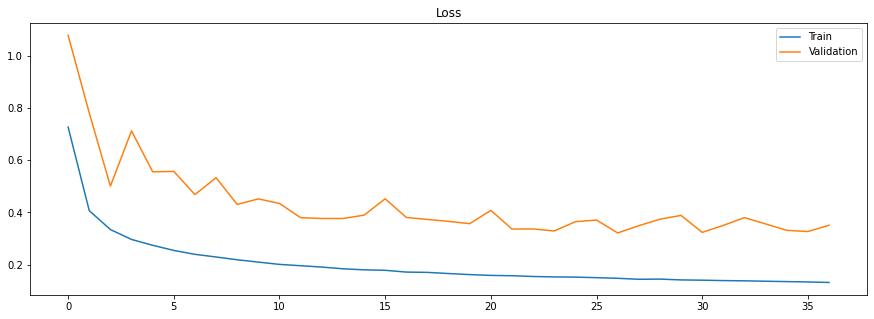

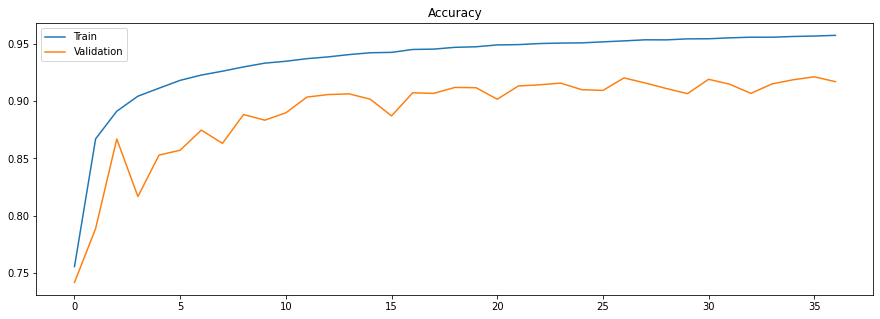

In [27]:
from pandas import read_csv
import matplotlib.pyplot as plt

plt.figure(figsize=(15,5))
plt.title("Loss")
plt.plot(history.history['loss'], label='Train')
plt.plot(history.history['val_loss'], label='Validation')
plt.legend()

plt.figure(figsize=(15,5))
plt.title("Accuracy")
plt.plot(history.history['accuracy'], label='Train')
plt.plot(history.history['val_accuracy'], label='Validation')
plt.legend()

<a name="5"></a>
# Evaluate best model

In [28]:
import tensorflow_addons as tfa
# load best model
trained_deep_model = tf.keras.models.load_model(join(config_model['checkpoint_path'] + config_model['network_name']))

<a name="5-1"></a>
### Train Dataset

In [29]:
test_performance = trained_deep_model.evaluate(train_dataset)
y_train, y_pred = utils.generate_data(train_dataset, trained_deep_model)

1234/1234 [==============================] - 109s 88ms/step - loss: 0.0254 - accuracy: 0.9919


  0% 0/1234 [00:00<?, ?it/s]

8/8 [==============================] - 1s 9ms/step


  0% 1/1234 [00:00<15:29,  1.33it/s]

8/8 [==============================] - 0s 2ms/step


  0% 2/1234 [00:00<09:18,  2.21it/s]

... (2,460 outputs left out)

8/8 [==============================] - 0s 4ms/step


100% 1233/1234 [04:55<00:00,  3.86it/s]

8/8 [==============================] - 0s 2ms/step


100% 1234/1234 [04:56<00:00,  4.17it/s]


In [30]:
pr, re, f1, acc=metrics.model_metrics(config_model['gesture_list'] ,y_train, y_pred, Get_metrics=True) 

              precision    recall  f1-score   support

           0       0.99      0.97      0.98     59566
           1       1.00      1.00      1.00     24523
           2       0.99      1.00      0.99     24356
           3       0.99      1.00      0.99     27024
           4       0.98      1.00      0.99     23292
           5       0.99      1.00      1.00     25182
           6       0.99      1.00      1.00     19580
           7       1.00      1.00      1.00     22140
          10       0.99      0.99      0.99     24538
          11       0.99      1.00      0.99     20692
          30       0.99      1.00      0.99     22485
          31       0.99      1.00      1.00     22526

    accuracy                           0.99    315904
   macro avg       0.99      1.00      0.99    315904
weighted avg       0.99      0.99      0.99    315904

Precision Score:  0.9920028997227361


/usr/local/lib/python3.8/dist-packages/sklearn/metrics/_classification.py:1298: UserWarning: Note that pos_label (set to 'positive') is ignored when average != 'binary' (got 'macro'). You may use labels=[pos_label] to specify a single positive class.
  warnings.warn("Note that pos_label (set to %r) is ignored when "
/usr/local/lib/python3.8/dist-packages/sklearn/metrics/_classification.py:1298: UserWarning: Note that pos_label (set to 'positive') is ignored when average != 'binary' (got 'macro'). You may use labels=[pos_label] to specify a single positive class.
  warnings.warn("Note that pos_label (set to %r) is ignored when "


Recall Score:  0.9953291540896836
F1-Score:  0.9936376249751855
Accuracy:  0.9919026033225283


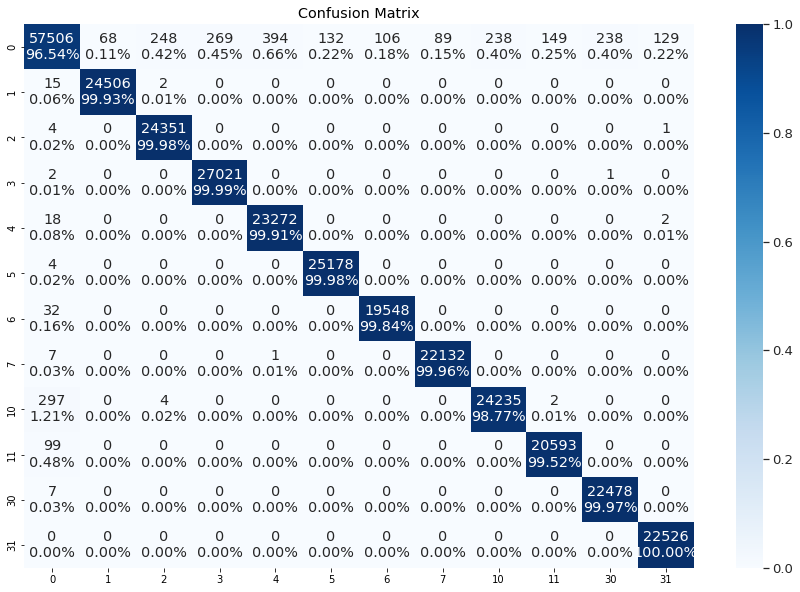

In [31]:
# available the train data 
cfm_deep_model=metrics.plot_confusion_matrix(config_model['gesture_list'], y_train, y_pred, Get_matrix=True)

<a name="5-2"></a>
### Test Dataset

In [32]:
test_performance = trained_deep_model.evaluate(test_dataset)
y_test, y_pred = utils.generate_data(test_dataset, trained_deep_model)

360/360 [==============================] - 32s 89ms/step - loss: 0.3566 - accuracy: 0.9089


  0% 0/360 [00:00<?, ?it/s]

8/8 [==============================] - 0s 2ms/step


  0% 1/360 [00:00<01:21,  4.42it/s]

8/8 [==============================] - 0s 2ms/step


  1% 2/360 [00:00<01:20,  4.46it/s]

... (712 outputs left out)

8/8 [==============================] - 0s 2ms/step


100% 359/360 [01:21<00:00,  4.34it/s]

8/8 [==============================] - 0s 2ms/step


100% 360/360 [01:21<00:00,  4.40it/s]


In [33]:
pr, re, f1, acc=metrics.model_metrics(config_model['gesture_list'] ,y_test, y_pred, Get_metrics=True) 

              precision    recall  f1-score   support

           0       0.95      0.84      0.89     37491
           1       0.90      0.98      0.94      4992
           2       0.90      0.96      0.93      5493
           3       0.93      0.99      0.96      5508
           4       0.91      0.94      0.93      4883
           5       0.91      0.99      0.95      5302
           6       0.82      0.96      0.89      4447
           7       0.89      0.96      0.92      4258
          10       0.83      0.85      0.84      4645
          11       0.86      0.92      0.89      4927
          30       0.84      0.98      0.91      4924
          31       0.92      0.98      0.95      5290

    accuracy                           0.91     92160
   macro avg       0.89      0.95      0.92     92160
weighted avg       0.91      0.91      0.91     92160

Precision Score:  0.8905449835303506
Recall Score:  0.9459299777500458
F1-Score:  0.9163757257121786
Accuracy:  0.9088433159722222


/usr/local/lib/python3.8/dist-packages/sklearn/metrics/_classification.py:1298: UserWarning: Note that pos_label (set to 'positive') is ignored when average != 'binary' (got 'macro'). You may use labels=[pos_label] to specify a single positive class.
  warnings.warn("Note that pos_label (set to %r) is ignored when "
/usr/local/lib/python3.8/dist-packages/sklearn/metrics/_classification.py:1298: UserWarning: Note that pos_label (set to 'positive') is ignored when average != 'binary' (got 'macro'). You may use labels=[pos_label] to specify a single positive class.
  warnings.warn("Note that pos_label (set to %r) is ignored when "


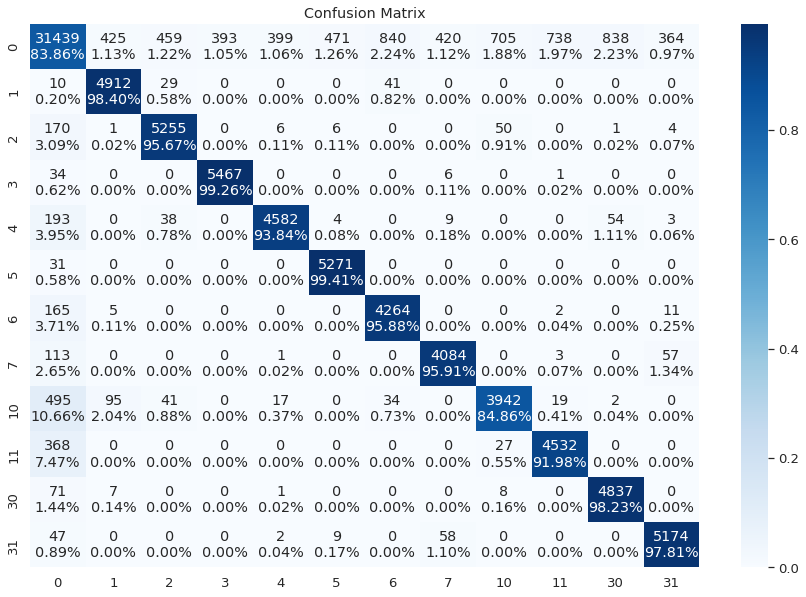

In [34]:
# available the test data 
cfm_deep_model=metrics.plot_confusion_matrix(config_model['gesture_list'], y_test, y_pred, Get_matrix=True)

#### Metrics with Average and std for each classes

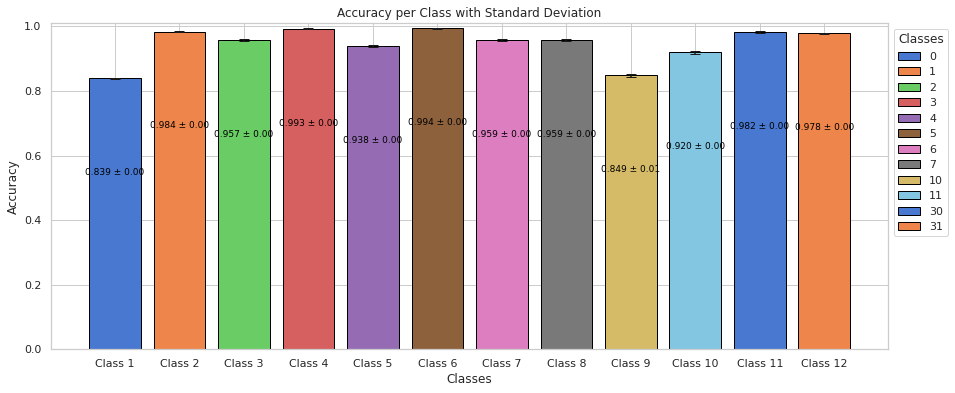

In [35]:
metrics.plot_metric_per_class(cfm_deep_model, config_model['gesture_list'], metric_name='Accuracy', method='per_class')

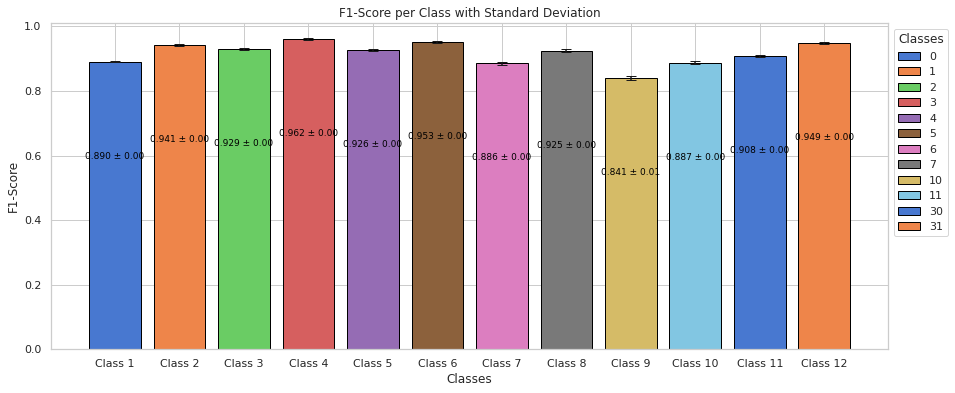

In [36]:
metrics.plot_metric_per_class(cfm_deep_model, config_model['gesture_list'], metric_name='F1-Score', method='per_class')

#### Mean and std for all Classes 

In [37]:
metrics_per_class,precision_list,recall_list,f1_score_list,accuracy_list=metrics.model_average_std_metrics(cf_matrix=cfm_deep_model, Get_metrics=True, Verbose=True) 

Precision Score: 0.8905±0.0396
Recall Score: 0.9459±0.0504
F1-Score: 0.9164±0.0338
Accuracy: 0.9459±0.0504


In [38]:
metrics_average_and_std_df=pd.DataFrame(data=[precision_list,recall_list,f1_score_list,accuracy_list],
             index=['pr', 're', 'f1', 'acc'],
             columns=['Average','std'])
metrics_average_and_std_df

,Average,std
pr,0.890545,0.039625
re,0.945930,0.050405
f1,0.916376,0.033775
acc,0.945930,0.050405


## ROC

ROC AUC for Class 0: 0.90377
ROC AUC for Class 1: 0.98893
ROC AUC for Class 2: 0.97506
ROC AUC for Class 3: 0.99401
ROC AUC for Class 4: 0.96674
ROC AUC for Class 5: 0.99426
ROC AUC for Class 6: 0.97421
ROC AUC for Class 7: 0.97676
ROC AUC for Class 8: 0.91981
ROC AUC for Class 9: 0.95554
ROC AUC for Class 10: 0.98604
ROC AUC for Class 11: 0.98651


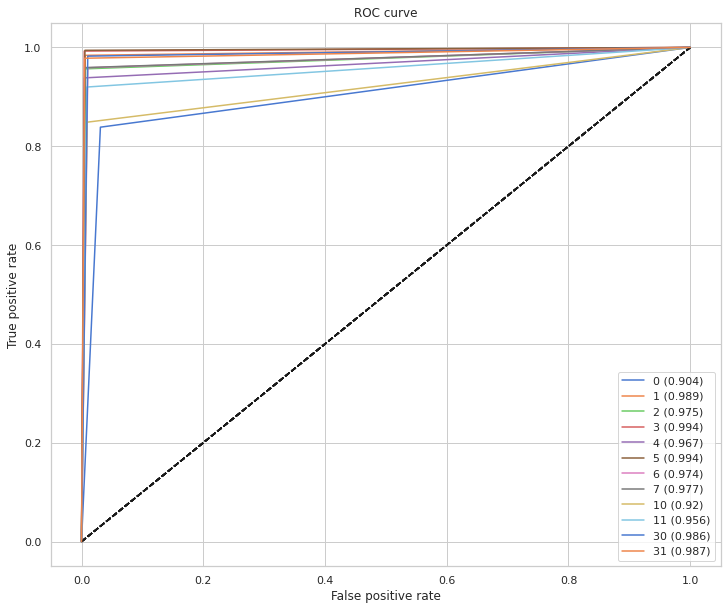

In [39]:
roc_score_per_class=metrics.get_roc_curve(config_model['gesture_list'], y_test, y_pred ,verbose=True)

In [40]:
# import mlflow_save_parameters_multiclass 

# mlflow_save_parameters_multiclass.save_data_in_mlflow("65HDsEMG_multiclass_armband", config_model, test_metric, data_processing.getProcessingNameList())

<a name="6"></a>
## Save the model in .H5 file

In [41]:
trained_deep_model.save(config_model['checkpoint_path'] +  config_model['network_name']+'/ResNet2D.h5')

In [42]:
config_model['checkpoint_path'] +  config_model['network_name']+'/ResNet2D.h5'

'trainings/EMG_HysersEMG_2D_CNN_128f_128ch_SCE_normminmax_bysample_adamW/ResNet2D.h5'